File Description

In [1]:
# ==============================================================================
# File Name: drug_knowledge_pipeline.ipynb
# Author: Habiba Ezat Abdeltawab
# Date of Creation: 22-07-2026
# Version Information: 1.0.0
# Dependencies: pandas, numpy, matplotlib, seaborn, scikit-learn, networkx
# Contributors: Habiba Ezat Abdeltawab
# Last Modified Date: 22-07-2026
# Description:Data processing and Machine Learning pipeline for the Drug Knowledge Base
#     and Expert System. Handles data loading, extensive cleaning, EDA,
#     feature engineering, and model training for drug safety prediction.
# ==============================================================================

Import Libraries

In [2]:
import os
import glob
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

Load and Merge Datasets

In [3]:
# Get current script directory or use relative path cleanly
current_dir = os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else os.getcwd()

# Dynamic datasets directory path
data_dir = os.path.join(current_dir, "datasets")
if not os.path.exists(data_dir):
    data_dir = current_dir  # Fallback to current directory
else:
    pass

# 1. Read and concatenate DDInter files from datasets folder
ddinter_files = glob.glob(os.path.join(data_dir, "ddinter_downloads_code_*.csv"))

if len(ddinter_files) > 0:
    try:
        ddinter_list = [pd.read_csv(file) for file in ddinter_files]
        ddinter_df = pd.concat(ddinter_list, ignore_index=True)
        print("DDInter datasets loaded and merged successfully.")
    except Exception as error:
        ddinter_df = pd.DataFrame()
        print(f"Failed to load DDInter datasets: {error}")
else:
    ddinter_df = pd.DataFrame()
    print(f"Warning: No DDInter files found in path: {data_dir}")

# 2. Read Drug Info file from datasets folder
drug_info_filename = "Drug finder db w_o brands - deepseek_csv_20250915_dff2b8.csv"
drug_info_path = os.path.join(data_dir, drug_info_filename)

if os.path.exists(drug_info_path):
    try:
        drug_info_df = pd.read_csv(drug_info_path)
        print("Drug info dataset loaded successfully.")
    except Exception as error:
        drug_info_df = pd.DataFrame()
        print(f"Failed to load Drug Info dataset: {error}")
else:
    drug_info_df = pd.DataFrame()
    print(f"Warning: File not found at path: {drug_info_path}")

DDInter datasets loaded and merged successfully.
Drug info dataset loaded successfully.


Show Data (ddinter_df)

In [4]:
ddinter_df.head()

,DDInterID_A,Drug_A,DDInterID_B,Drug_B,Level
0,DDInter1263,Naltrexone,DDInter1,Abacavir,Moderate
1,DDInter1,Abacavir,DDInter1348,Orlistat,Moderate
2,DDInter58,Aluminum hydroxide,DDInter582,Dolutegravir,Major
3,DDInter112,Aprepitant,DDInter582,Dolutegravir,Minor
4,DDInter138,Attapulgite,DDInter582,Dolutegravir,Major


In [5]:
ddinter_df.tail()

,DDInterID_A,Drug_A,DDInterID_B,Drug_B,Level
222378,DDInter513,Dexamethasone,DDInter801,Galactose,Unknown
222379,DDInter1683,Sodium bicarbonate,DDInter801,Galactose,Unknown
222380,DDInter317,Cefepime,DDInter801,Galactose,Unknown
222381,DDInter1906,Ursodeoxycholic acid,DDInter801,Galactose,Unknown
222382,DDInter1663,Sevelamer,DDInter766,Fluticasone,Unknown


In [6]:
ddinter_df.describe().T

,count,unique,top,freq
DDInterID_A,222383,1770,DDInter1513,2092
Drug_A,222383,1770,Prednisolone,2092
DDInterID_B,222383,1858,DDInter513,2426
Drug_B,222383,1858,Dexamethasone,2426
Level,222383,4,Moderate,130367


In [7]:
ddinter_df['Level'].value_counts()

Level
Moderate    130367
Unknown      47182
Major        33896
Minor        10938
Name: count, dtype: int64

In [8]:
ddinter_df.shape

(222383, 5)

In [9]:
ddinter_df.nunique()

DDInterID_A    1770
Drug_A         1770
DDInterID_B    1858
Drug_B         1858
Level             4
dtype: int64

In [10]:
ddinter_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222383 entries, 0 to 222382
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   DDInterID_A  222383 non-null  object
 1   Drug_A       222383 non-null  object
 2   DDInterID_B  222383 non-null  object
 3   Drug_B       222383 non-null  object
 4   Level        222383 non-null  object
dtypes: object(5)
memory usage: 8.5+ MB


Show Data (drug_info_df)

In [11]:
drug_info_df.head()

,Generic Name,Drug Class,Indications,Dosage Form,Strength,Route of Administration,Side Effects,Contraindications,Interaction warnings & Precautions,Storage Conditions,Pregnancy Category,Reference,Availability
0,Acyclovir,Antiviral,Herpes simplex virus (HSV) infections,Tablet,400 mg,Oral,Varicella zoster virus (VZV) infections,Nausea,Probenecid may decrease acyclovir clearance in...,Room Temperature,Human studies have proved safety,"Lexicomp, Micromedex",Prescription
1,Adalimumab,TNF Blocker,Autoimmune disorders (RA,Solution,40 mg/0.8 mL,Subcutaneous,Crohn's,psoriasis,Live vaccines should not be given concurrently...,Refrigerate Do Not Freeze Protect from light,Animal studies have demonstrated safety,"FDA Prescribing Information, Briggs",Prescription
2,Adapalene,Retinoid,Acne vulgaris,Gel,0.10%,Topical,Skin dryness,erythema,No major systemic drug interactions due to min...,Room Temperature,Contraindicated (not allowed),"FDA Prescribing Information, Avoid topical use...",No prescription required
3,Albendazole,Anthelmintic,Parasitic worm infections,Tablet,200 mg,Oral,Abdominal pain,nausea,Cimetidine praziquantel and dexamethasone can ...,Room Temperature,Contraindicated (not allowed),FDA Prescribing Information,Prescription
4,Albuterol-Ipratropium,SABA + Anticholinergic,COPD,Solution for Nebulization,3 mL/3 mL (0.5/2.5),Inhalation,bronchospasm,Cough,Beta-blockers may antagonize the effects of al...,Room Temperature,Animal studies have demonstrated safety,"Lexicomp, Micromedex",Prescription


In [12]:
drug_info_df.tail()

,Generic Name,Drug Class,Indications,Dosage Form,Strength,Route of Administration,Side Effects,Contraindications,Interaction warnings & Precautions,Storage Conditions,Pregnancy Category,Reference,Availability
713,Ziprasidone,Atypical Antipsychotic,Schizophrenia,Capsule,40 mg,Oral,bipolar disorder,Somnolence,Other drugs that prolong the QT interval are c...,Room Temperature,Animal studies have demonstrated safety,FDA Prescribing Information,Prescription
714,Zoledronic Acid,Bisphosphonate,Hypercalcemia of malignancy,Solution,5 mg/100 mL,Intravenous,bone metastases,Flu-like symptoms,Nephrotoxic drugs may increase risk of renal i...,Room Temperature,Contraindicated (not allowed),FDA Prescribing Information,Prescription
715,Zolmitriptan,5-HT1 Agonist,Migraine attacks,Tablet,2.5 mg,Oral,Dizziness,somnolence,Other 5-HT1 agonists and MAOIs can have additi...,Room Temperature,Contraindicated (not allowed),FDA Prescribing Information,Prescription
716,Zolpidem,Non-Benzodiazepine Hypnotic,Insomnia,Tablet,10 mg,Oral,Dizziness,somnolence,CNS depressants including alcohol increase sed...,Room Temperature,Animal studies have demonstrated safety,FDA Prescribing Information,Prescription
717,Zonisamide,Anticonvulsant,Seizures,Capsule,100 mg,Oral,Somnolence,dizziness,Strong CYP3A4 inducers may decrease levels Can...,Room Temperature,Animal studies have proved adverse effects but...,FDA Prescribing Information,Prescription


In [13]:
drug_info_df.describe().T

,count,unique,top,freq
Generic Name,718,718,Zonisamide,1
Drug Class,718,276,Anticonvulsant,18
Indications,718,251,Hypertension,50
Dosage Form,718,33,Tablet,390
Strength,718,187,500 mg,50
Route of Administration,718,17,Oral,518
Side Effects,718,245,Nausea,53
Contraindications,718,213,nausea,84
Interaction warnings & Precautions,718,545,ACE inhibitors and ARBs may have diminished an...,14
Storage Conditions,718,7,Room Temperature,672


In [14]:
drug_info_df.shape

(718, 13)

In [15]:
drug_info_df.nunique()

Generic Name                          718
Drug Class                            276
Indications                           251
Dosage Form                            33
Strength                              187
Route of Administration                17
Side Effects                          245
Contraindications                     213
Interaction warnings & Precautions    545
Storage Conditions                      7
Pregnancy Category                      5
Reference                              50
Availability                            5
dtype: int64

In [16]:
drug_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 718 entries, 0 to 717
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Generic Name                        718 non-null    object
 1   Drug Class                          718 non-null    object
 2   Indications                         718 non-null    object
 3   Dosage Form                         718 non-null    object
 4   Strength                            718 non-null    object
 5   Route of Administration             718 non-null    object
 6   Side Effects                        718 non-null    object
 7   Contraindications                   718 non-null    object
 8   Interaction warnings & Precautions  718 non-null    object
 9   Storage Conditions                  718 non-null    object
 10  Pregnancy Category                  718 non-null    object
 11  Reference                           718 non-null    object

Data Cleaning

Check For Missing Values In Both Datasets

In [17]:
print(f'Drug Info Dataset:\n{drug_info_df.isnull().sum()}')
print('='*30)
print(f'ddinter Dataset:\n{ddinter_df.isnull().sum()}')

Drug Info Dataset:
Generic Name                          0
Drug Class                            0
Indications                           0
Dosage Form                           0
Strength                              0
Route of Administration               0
Side Effects                          0
Contraindications                     0
Interaction warnings & Precautions    0
Storage Conditions                    0
Pregnancy Category                    0
Reference                             0
Availability                          0
dtype: int64
ddinter Dataset:
DDInterID_A    0
Drug_A         0
DDInterID_B    0
Drug_B         0
Level          0
dtype: int64


Check For Duplicated Values In Both Datasets

In [18]:
print(f'ddinter Dataset Duplicated:{ddinter_df.duplicated().sum()}')
print(f'Drug Duplicated:{drug_info_df.duplicated().sum()}')

ddinter Dataset Duplicated:62148
Drug Duplicated:0


Remove Duplicated Values

In [19]:
ddinter_df.drop_duplicates(inplace=True)

Text Normalization 

In [20]:
# ------------------------------------------------------------------------------
# Text Normalization (strip white spaces and convert to lower case)
# ------------------------------------------------------------------------------
try:
    # Normalize string columns in ddinter_df
    for column_name in ddinter_df.columns:
        if ddinter_df[column_name].dtype == 'object':
            ddinter_df[column_name] = ddinter_df[column_name].astype(str).str.strip().str.lower()
        else:
            pass

    # Normalize string columns in drug_info_df
    for column_name in drug_info_df.columns:
        if drug_info_df[column_name].dtype == 'object':
            drug_info_df[column_name] = drug_info_df[column_name].astype(str).str.strip().str.lower()
        else:
            pass
            
    print("Text normalization (strip and lower) completed successfully.")
except Exception as normalization_error:
    print(f"Error during text normalization: {normalization_error}")
else:
    pass

Text normalization (strip and lower) completed successfully.


 Handling 'unknown' values in 'Level' column

In [21]:
# ------------------------------------------------------------------------------
# Handling 'unknown' values in 'Level' column
# ------------------------------------------------------------------------------
try:
    initial_rows_count = len(ddinter_df)

    if "Level" in ddinter_df.columns:
        ddinter_df = ddinter_df[ddinter_df["Level"] != "unknown"].copy()
        removed_rows_count = initial_rows_count - len(ddinter_df)
        print(f"Removed {removed_rows_count} rows containing 'unknown' severity levels.")
    else:
        print("Warning: 'Level' column not found in ddinter_df.")
except Exception as cleaning_error:
    print(f"Error handling unknown levels: {cleaning_error}")
else:
    pass

Removed 29813 rows containing 'unknown' severity levels.


EDA (Exploratory Data Analysis)

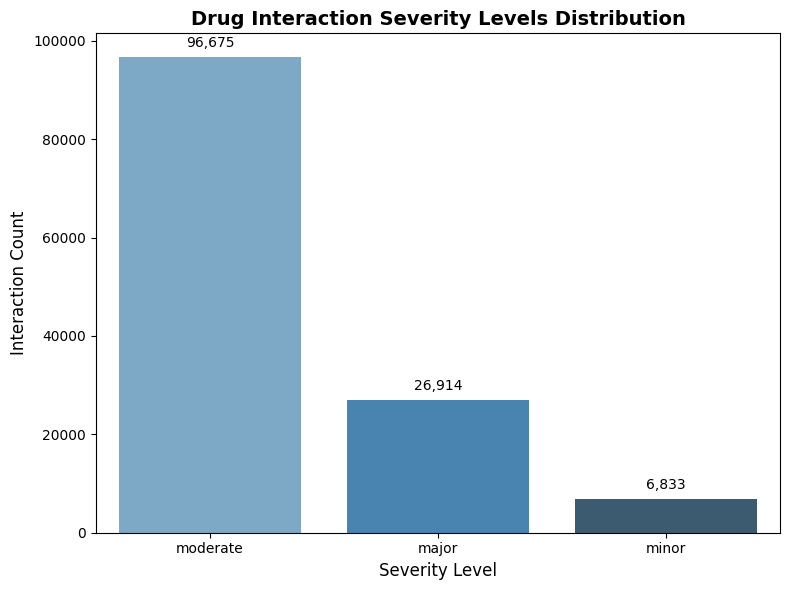

In [22]:
# ------------------------------------------------------------------------------
# 1. Severity Level Categorization Distribution 
# ------------------------------------------------------------------------------
plt.figure(figsize=(8, 6))
level_counts = ddinter_df['Level'].value_counts()

ax = sns.barplot(x=level_counts.index, y=level_counts.values, palette='Blues_d')
plt.title('Drug Interaction Severity Levels Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Severity Level', fontsize=12)
plt.ylabel('Interaction Count', fontsize=12)

# Add value labels on top of bars
for bar in ax.patches:
    ax.annotate(f'{int(bar.get_height()):,}',
                (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

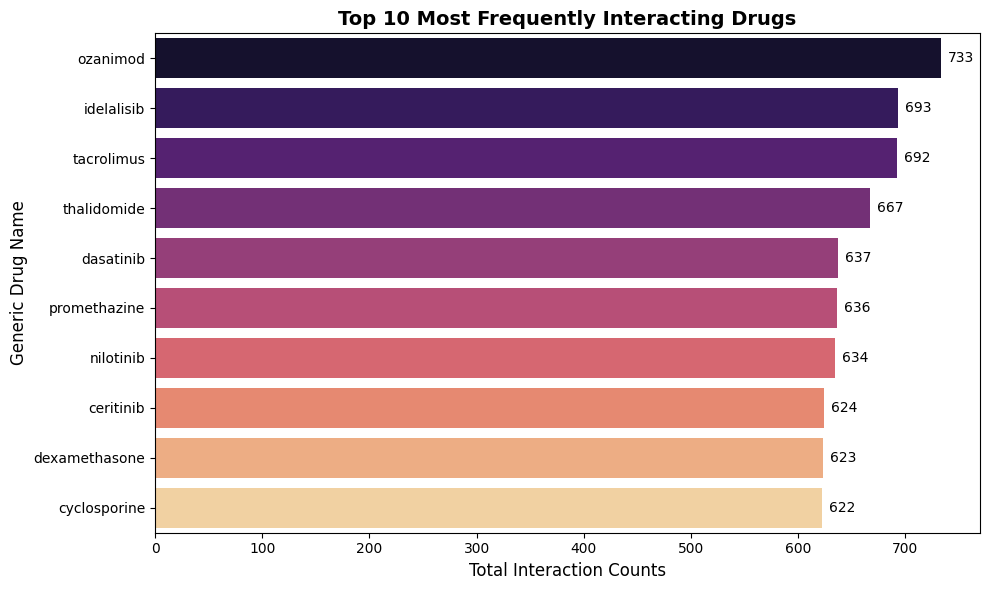

In [23]:
# ------------------------------------------------------------------------------
# 2. Top 10 Most Interacting Drugs
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))

# Combine both drug columns to find overall most frequent drugs
all_interacting_drugs = pd.concat([ddinter_df['Drug_A'], ddinter_df['Drug_B']])
top_drugs = all_interacting_drugs.value_counts().head(10)

ax = sns.barplot(x=top_drugs.values, y=top_drugs.index, palette='magma')
plt.title('Top 10 Most Frequently Interacting Drugs', fontsize=14, fontweight='bold')
plt.xlabel('Total Interaction Counts', fontsize=12)
plt.ylabel('Generic Drug Name', fontsize=12)

# Add value labels on bars
for bar in ax.patches:
    ax.annotate(f'{int(bar.get_width()):,}',
                (bar.get_width(), bar.get_y() + bar.get_height() / 2.),
                ha='left', va='center', fontsize=10, xytext=(5, 0),
                textcoords='offset points')

plt.tight_layout()
plt.show()

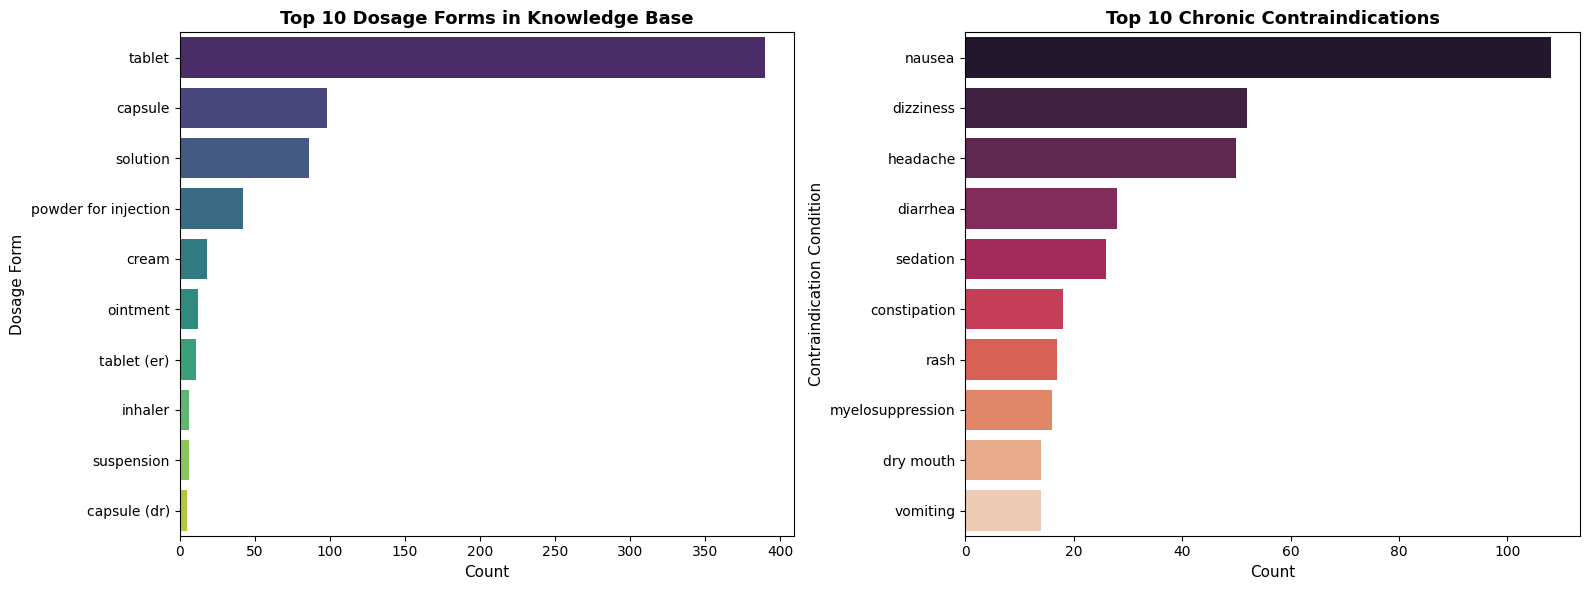

In [24]:
# ------------------------------------------------------------------------------
# 3. Top Indications & Contraindications Analysis 
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Top 10 Dosage Forms
top_dosage = drug_info_df['Dosage Form'].value_counts().head(10)
sns.barplot(ax=axes[0], x=top_dosage.values, y=top_dosage.index, palette='viridis')
axes[0].set_title('Top 10 Dosage Forms in Knowledge Base', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Count', fontsize=11)
axes[0].set_ylabel('Dosage Form', fontsize=11)

# Plot Top 10 Contraindications
top_contra = drug_info_df['Contraindications'].value_counts().head(10)
sns.barplot(ax=axes[1], x=top_contra.values, y=top_contra.index, palette='rocket')
axes[1].set_title('Top 10 Chronic Contraindications', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Count', fontsize=11)
axes[1].set_ylabel('Contraindication Condition', fontsize=11)

plt.tight_layout()
plt.show()

Knowledge Graph

In [25]:
# ==============================================================================
# Step 1: Knowledge Graph Construction
# ==============================================================================

# Initialize an undirected Graph
knowledge_graph = nx.Graph()

# ------------------------------------------------------------------------------
# 1. Add Drug-Drug Interaction (DDI) Edges from ddinter_df
# ------------------------------------------------------------------------------
for _, row in ddinter_df.iterrows():
    drug_a = row['Drug_A']
    drug_b = row['Drug_B']
    severity = row['Level']
    
    # Add nodes and edge with attributes
    knowledge_graph.add_edge(
        drug_a, 
        drug_b, 
        relationship='INTERACTS_WITH', 
        severity=severity
    )

# ------------------------------------------------------------------------------
# 2. Add Drug-Contraindication Edges from drug_info_df
# ------------------------------------------------------------------------------
if 'Contraindications' in drug_info_df.columns:
    for _, row in drug_info_df.iterrows():
        drug_name = str(row['Drug Name']).strip().lower() if 'Drug Name' in drug_info_df.columns else None
        contraindications = row['Contraindications']
        
        if pd.notna(contraindications) and drug_name:
            # Parse contraindication string into individual conditions
            conditions = [c.strip().lower() for c in str(contraindications).split(',') if c.strip()]
            
            for condition in conditions:
                knowledge_graph.add_edge(
                    drug_name, 
                    condition, 
                    relationship='CONTRAINDICATED_WITH'
                )

In [26]:
# ------------------------------------------------------------------------------
# Graph Summary & Statistics
# ------------------------------------------------------------------------------
print("=== Knowledge Graph Summary ===")
print(f"Total Nodes (Drugs & Conditions): {knowledge_graph.number_of_nodes():,}")
print(f"Total Edges (Interactions & Contraindications): {knowledge_graph.number_of_edges():,}")

=== Knowledge Graph Summary ===
Total Nodes (Drugs & Conditions): 1,902
Total Edges (Interactions & Contraindications): 130,422


In [27]:
# ==============================================================================
# Step 2: Feature Engineering - Graph Metrics Extraction
# ==============================================================================

try:
    # Calculate degree and centrality for all nodes in the knowledge graph
    node_degrees = dict(knowledge_graph.degree())
    node_centralities = nx.degree_centrality(knowledge_graph)

    # Map graph features to Drug_A
    ddinter_df["drug_a_degree"] = ddinter_df["Drug_A"].map(node_degrees).fillna(0)
    ddinter_df["drug_a_centrality"] = ddinter_df["Drug_A"].map(node_centralities).fillna(0)

    # Map graph features to Drug_B
    ddinter_df["drug_b_degree"] = ddinter_df["Drug_B"].map(node_degrees).fillna(0)
    ddinter_df["drug_b_centrality"] = ddinter_df["Drug_B"].map(node_centralities).fillna(0)

    # Interaction Pair Combined Features
    ddinter_df["pair_total_degree"] = ddinter_df["drug_a_degree"] + ddinter_df["drug_b_degree"]
    ddinter_df["pair_centrality_product"] = ddinter_df["drug_a_centrality"] * ddinter_df["drug_b_centrality"]

    print("Graph features successfully extracted and merged into ddinter_df.")
    print("New Graph Features Added:")
    print("- drug_a_degree & drug_b_degree")
    print("- drug_a_centrality & drug_b_centrality")
    print("- pair_total_degree & pair_centrality_product")

except Exception as feature_error:
    print(f"Error during Graph Feature Engineering: {feature_error}")
else:
    pass

Graph features successfully extracted and merged into ddinter_df.
New Graph Features Added:
- drug_a_degree & drug_b_degree
- drug_a_centrality & drug_b_centrality
- pair_total_degree & pair_centrality_product


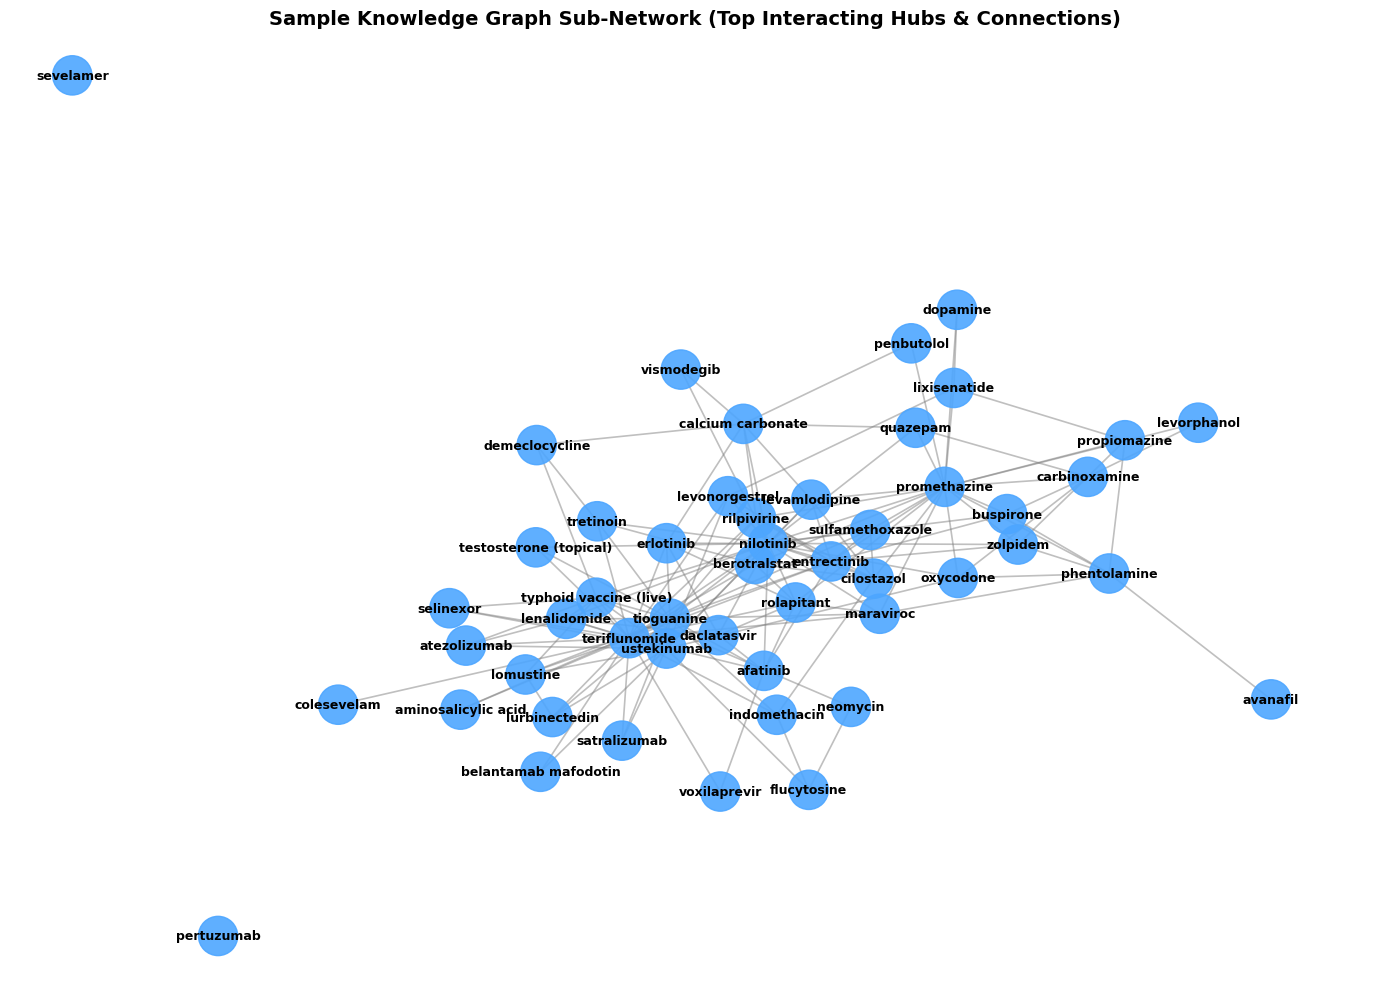

In [28]:
# ==============================================================================
# Knowledge Graph Sub-graph Visualization
# ==============================================================================

try:
    # 1. Select a focus node (e.g., top interacted drug) or a sample of highly connected nodes
    top_drugs = [node for node, degree in sorted(knowledge_graph.degree(), key=lambda x: x[1], reverse=True)[:3]]
    
    # Collect nodes within 1-hop neighborhood of top drugs
    subgraph_nodes = set(top_drugs)
    for drug in top_drugs:
        subgraph_nodes.update(knowledge_graph.neighbors(drug))
        
    # Extract sub-graph (limit to 50 nodes for clear visualization)
    subgraph_nodes = list(subgraph_nodes)[:50]
    sub_g = knowledge_graph.subgraph(subgraph_nodes)

    # 2. Define node colors (Drugs vs Conditions/Contraindications)
    node_colors = []
    for node in sub_g.nodes():
        if node in top_drugs:
            node_colors.append('#ff4d4d')  # Red for Top Focus Drugs
        elif any(sub_g.has_edge(node, target) and sub_g[node][target].get('relationship') == 'CONTRAINDICATED_WITH' for target in sub_g.nodes()):
            node_colors.append('#ffb380')  # Orange for Contraindications/Conditions
        else:
            node_colors.append('#4da6ff')  # Blue for Other Interacting Drugs

    # 3. Plot the sub-graph
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(sub_g, k=0.3, seed=42)
    
    nx.draw_networkx_nodes(sub_g, pos, node_color=node_colors, node_size=800, alpha=0.9)
    nx.draw_networkx_edges(sub_g, pos, edge_color='gray', alpha=0.5, width=1.2)
    nx.draw_networkx_labels(sub_g, pos, font_size=9, font_weight='bold')

    plt.title("Sample Knowledge Graph Sub-Network (Top Interacting Hubs & Connections)", fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

except Exception as viz_error:
    print(f"Error visualizing Knowledge Graph: {viz_error}")
else:
    pass

Data Preprocessing

In [29]:
# ==============================================================================
# Step 3: Data Preprocessing (Encoding , Scaling)
# ==============================================================================

# 1. Merge Drug Info for Drug_A
merged_df = ddinter_df.merge(
    drug_info_df, 
    left_on='Drug_A', 
    right_on='Generic Name', 
    how='left', 
    suffixes=('', '_A')
)

# 2. Merge Drug Info for Drug_B
merged_df = merged_df.merge(
    drug_info_df, 
    left_on='Drug_B', 
    right_on='Generic Name', 
    how='left', 
    suffixes=('_A', '_B')
)

if 'Generic Name' in merged_df.columns:
    merged_df.rename(columns={'Generic Name': 'Generic Name_A'}, inplace=True)

# ------------------------------------------------------------------------------
# Advanced Feature Extraction (13 Columns)
# ------------------------------------------------------------------------------

# Feature 1: Is Same Drug Class?
merged_df['is_same_class'] = (
    (merged_df['Drug Class_A'].notna()) & 
    (merged_df['Drug Class_A'] == merged_df['Drug Class_B'])
).astype(int)

# Feature 2: Pregnancy Risk Ordinal Mapping
preg_map = {'a': 1, 'b': 2, 'c': 3, 'd': 4, 'x': 5, 'n': 0}
merged_df['preg_cat_A'] = merged_df['Pregnancy Category_A'].str.lower().map(preg_map).fillna(0)
merged_df['preg_cat_B'] = merged_df['Pregnancy Category_B'].str.lower().map(preg_map).fillna(0)
merged_df['max_preg_risk'] = merged_df[['preg_cat_A', 'preg_cat_B']].max(axis=1)

# Feature 3: Text Lengths
merged_df['side_effects_len_A'] = merged_df['Side Effects_A'].fillna('').str.len()
merged_df['side_effects_len_B'] = merged_df['Side Effects_B'].fillna('').str.len()

# Feature 4: Frequency Encoding
for col in ['Drug_A', 'Drug_B', 'DDInterID_A', 'DDInterID_B', 'Drug Class_A', 'Drug Class_B']:
    freq_map = merged_df[col].value_counts(normalize=True).to_dict()
    merged_df[f'{col}_freq'] = merged_df[col].map(freq_map).fillna(0)

# Feature 5: Stronger TF-IDF Vectorizer (100 Features)
merged_df['combined_medical_text'] = (
    merged_df['Indications_A'].fillna('') + " " + 
    merged_df['Contraindications_A'].fillna('') + " " +
    merged_df['Indications_B'].fillna('') + " " + 
    merged_df['Contraindications_B'].fillna('')
)

tfidf = TfidfVectorizer(max_features=100, stop_words='english')
tfidf_features = tfidf.fit_transform(merged_df['combined_medical_text']).toarray()
tfidf_feature_names = [f"tfidf_{i}" for i in range(tfidf_features.shape[1])]
tfidf_df = pd.DataFrame(tfidf_features, columns=tfidf_feature_names, index=merged_df.index)

# Structuring Feature Matrix
structured_features = [
    'Drug_A_freq', 'Drug_B_freq', 'DDInterID_A_freq', 'DDInterID_B_freq',
    'Drug Class_A_freq', 'Drug Class_B_freq',
    'drug_a_degree', 'drug_a_centrality', 'drug_b_degree', 'drug_b_centrality',
    'pair_total_degree', 'pair_centrality_product',
    'is_same_class', 'preg_cat_A', 'preg_cat_B', 'max_preg_risk',
    'side_effects_len_A', 'side_effects_len_B'
]

X_all = pd.concat([merged_df[structured_features], tfidf_df], axis=1)

# Target Encoding
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(merged_df['Level'])
level_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_all.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_all.columns)

print("Preprocessing Complete!")
print(f"Train set shape: {X_train_scaled.shape}")
print(f"Test set shape : {X_test_scaled.shape}")

Preprocessing Complete!
Train set shape: (104337, 118)
Test set shape : (26085, 118)


Model Training & Evaluation

In [30]:
# Calculate class weights for Imbalanced handling
class_counts = np.bincount(y_train)
class_weights = len(y_train) / (len(class_counts) * class_counts)
sample_weights = np.array([dict(enumerate(class_weights))[val] for val in y_train])

Model Training and Evaluation Balanced

Training Random Forest (Optimized)...

Random Forest Evaluation Report (Optimized)
Training Accuracy : 0.8205
Testing Accuracy  : 0.7468

Classification Report:
              precision    recall  f1-score   support

       major       0.52      0.72      0.60      5383
       minor       0.40      0.64      0.49      1367
    moderate       0.89      0.76      0.82     19335

    accuracy                           0.75     26085
   macro avg       0.61      0.71      0.64     26085
weighted avg       0.79      0.75      0.76     26085

Training XGBoost (Optimized)...

XGBoost Evaluation Report (Optimized)
Training Accuracy : 0.7479
Testing Accuracy  : 0.7169

Classification Report:
              precision    recall  f1-score   support

       major       0.54      0.77      0.63      5383
       minor       0.29      0.80      0.42      1367
    moderate       0.93      0.70      0.80     19335

    accuracy                           0.72     26085
   macro avg       0.58      0.75    

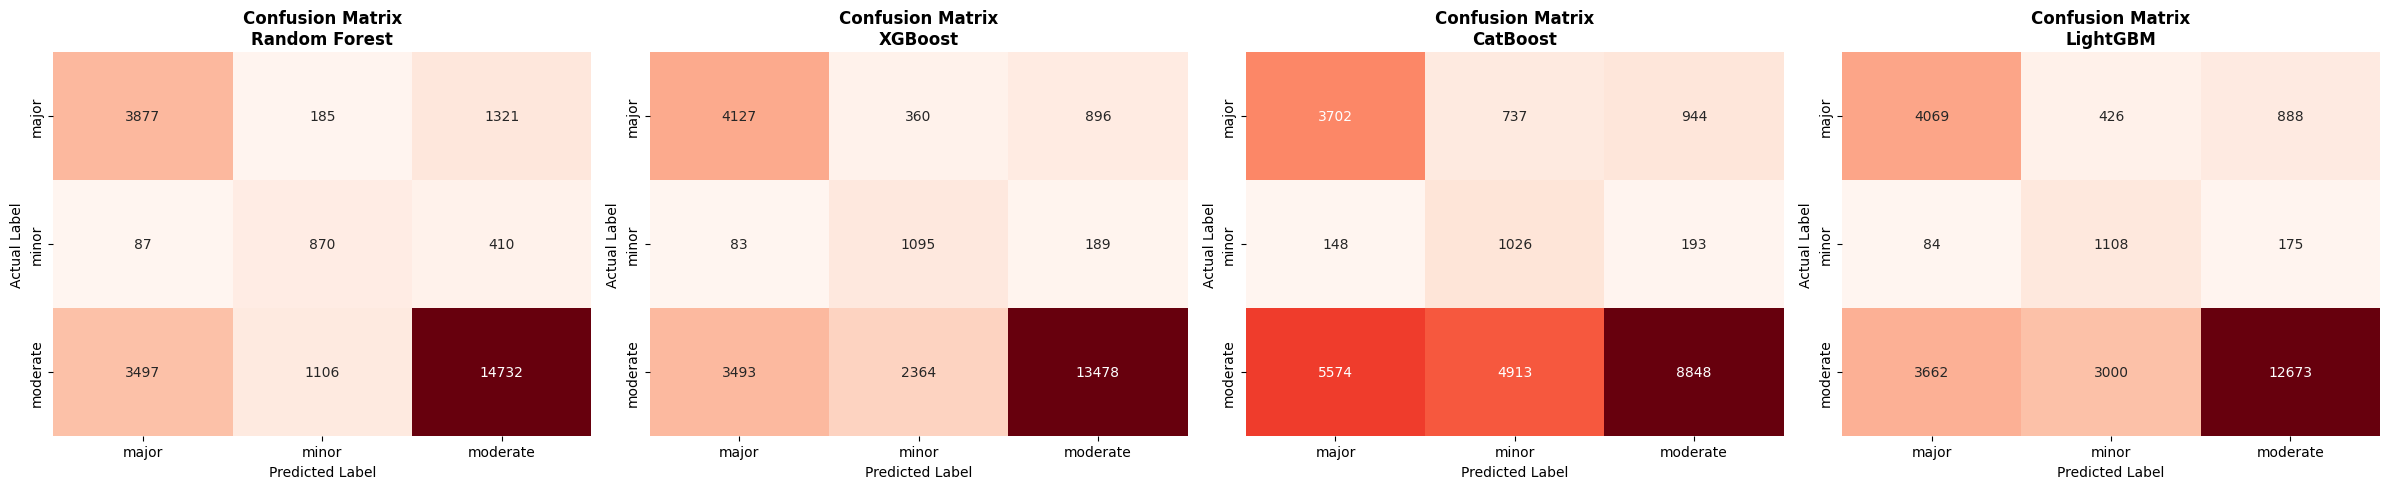

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.820533,0.746751,0.791626,0.746751,0.760509
1,XGBoost,0.747865,0.716887,0.811595,0.716887,0.741728
2,CatBoost,0.527838,0.520452,0.745945,0.520452,0.563927
3,LightGBM,0.703250,0.684301,0.804121,0.684301,0.715013


In [31]:
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_split=4, min_samples_leaf=2,
        class_weight='balanced_subsample', random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=150, learning_rate=0.08, max_depth=8, subsample=0.8,
        colsample_bytree=0.8, random_state=42, n_jobs=-1, eval_metric='mlogloss'
    ),
    'CatBoost': CatBoostClassifier(
        iterations=150, learning_rate=0.08, depth=7, random_state=42,
        class_weights=class_weights, verbose=0
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=8, num_leaves=45,
        class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1
    )
}

target_names = [class_name for class_name, _ in sorted(level_mapping.items(), key=lambda x: x[1])]
results = []

plt.figure(figsize=(24, 5))

for i, (name, model) in enumerate(models.items()):
    print(f"Training {name} (Optimized)...")
    if name == 'XGBoost':
        model.fit(X_train_scaled, y_train, sample_weight=sample_weights)
    else:
        model.fit(X_train_scaled, y_train)

    train_acc = model.score(X_train_scaled, y_train)
    test_acc = model.score(X_test_scaled, y_test)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results.append([name, train_acc, test_acc, prec, rec, f1])

    print(f"\n{'='*45}\n{name} Evaluation Report (Optimized)\n{'='*45}")
    print(f"Training Accuracy : {train_acc:.4f}")
    print(f"Testing Accuracy  : {test_acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=target_names))

    # Confusion Matrix Visualization
    plt.subplot(1, 4, i+1)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
                xticklabels=target_names, yticklabels=target_names)
    plt.title(f'Confusion Matrix\n{name}', fontsize=12, fontweight='bold')
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Display Final Comparison Table
summary_df = pd.DataFrame(
    results, 
    columns=['Model', 'Train Accuracy', 'Test Accuracy', 'Precision', 'Recall', 'F1-Score']
)
display(summary_df)

Feature Importance Analysis

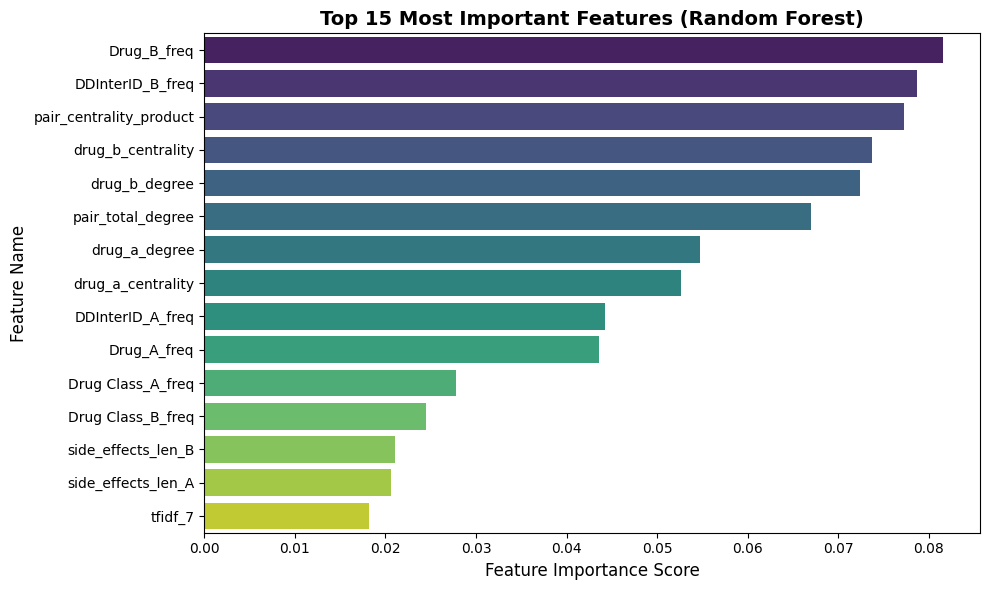


=== Top 10 Influential Features ===
                Feature  Importance
            Drug_B_freq    0.081575
       DDInterID_B_freq    0.078648
pair_centrality_product    0.077224
      drug_b_centrality    0.073696
          drug_b_degree    0.072435
      pair_total_degree    0.066981
          drug_a_degree    0.054688
      drug_a_centrality    0.052630
       DDInterID_A_freq    0.044258
            Drug_A_freq    0.043623


In [32]:
# 1. Extract Feature Importances from Champion Model (Random Forest)
champion_model = models['Random Forest']
importances = champion_model.feature_importances_
feature_names = X_all.columns

# Create DataFrame for Top Features
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot Top 15 Most Important Features
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_imp_df.head(15), 
    palette='viridis'
)
plt.title('Top 15 Most Important Features (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

# Print Top 10 Features in Console
print("\n=== Top 10 Influential Features ===")
print(feature_imp_df.head(10).to_string(index=False))

Save Model Assets for Deployment

In [33]:
# Create saved_models folder relative to the script location
models_dir = os.path.join(current_dir, "saved_models")
os.makedirs(models_dir, exist_ok=True)

# Save Pipeline Components
joblib.dump(champion_model, os.path.join(models_dir, 'random_forest_ddi_model.pkl'))
joblib.dump(scaler, os.path.join(models_dir, 'scaler.pkl'))
joblib.dump(label_encoder, os.path.join(models_dir, 'label_encoder.pkl'))
joblib.dump(tfidf, os.path.join(models_dir, 'tfidf_vectorizer.pkl'))

print(f"\n=== Champion Model & Assets Saved Successfully in: '{models_dir}' ===")


=== Champion Model & Assets Saved Successfully in: 'c:\Users\ezath\OneDrive\Desktop\Drug_Knowledge_base\saved_models' ===


For Test 

In [34]:
drug_info_df[drug_info_df['Generic Name'].astype(str).str.lower().str.strip() == 'warfarin'].T

,707
Generic Name,warfarin
Drug Class,anticoagulant (vitamin k antagonist)
Indications,thromboembolism prevention/treatment
Dosage Form,tablet
Strength,5 mg
Route of Administration,oral
Side Effects,bleeding
Contraindications,skin necrosis
Interaction warnings & Precautions,a vast number of drugs can increase or decreas...
Storage Conditions,room temperature
